# AgriOptima: Crop suitability

Seven measurements predict one crop label. Logistic Regression and SVM are compared below. Classification accuracy means agreement with dataset labels, not proof of the best profitable crop. Some classes, including chickpea, have weak recall.

Run each cell in order. This notebook trains its own evaluation model and does not overwrite application artifacts.

## 1. Import libraries and find the project
Pandas reads tables; NumPy handles numbers; Matplotlib draws figures.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when Jupyter starts in the project root or this notebook folder.
ROOT = Path.cwd()
if not (ROOT / 'DataSets').exists():
    ROOT = ROOT.parent
assert (ROOT / 'DataSets').exists(), 'Open Jupyter in the project folder.'

## 2. Read, inspect and clean raw data
The source CSVs remain unchanged. Invalid rows and duplicate handling are visible below. Earlier audit records are preserved in the recovery copy outside this project.

In [2]:
raw = pd.read_csv(ROOT / 'DataSets/crop_suitability.csv')
display(raw.head())
print('Raw rows:', len(raw), 'Duplicates:', raw.duplicated().sum())
display(raw.isna().sum())
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
data = raw.copy()
for column in features:
    data[column] = pd.to_numeric(data[column], errors='coerce')
data['label'] = data['label'].astype('string').str.strip()
valid = np.isfinite(data[features]).all(axis=1) & data['label'].notna() & data['label'].ne('')
data = data.loc[valid, features + ['label']].drop_duplicates().reset_index(drop=True)
print('Clean rows:', len(data))

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


Raw rows: 3130 Duplicates: 0


N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Clean rows: 3130


### Look at the data
This overview describes the dataset. It is not a prediction result.

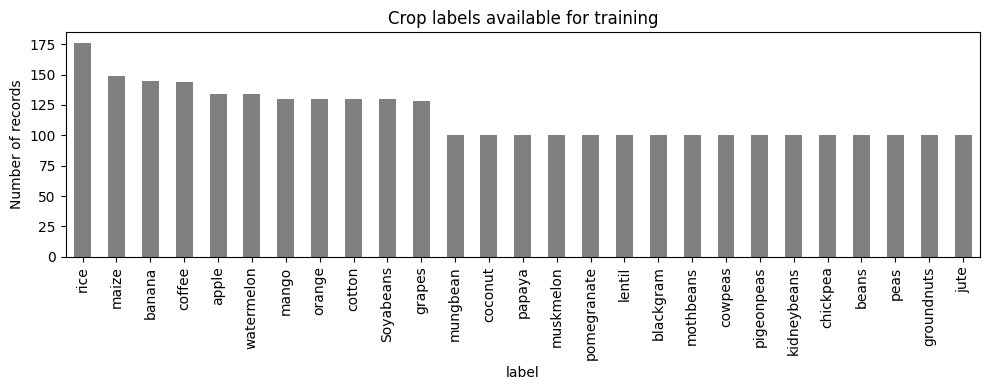

In [3]:
data['label'].value_counts().plot.bar(figsize=(10, 4), color='gray')
plt.ylabel('Number of records')
plt.title('Crop labels available for training')
plt.tight_layout()
plt.show()

Each bar counts examples of a crop. This shows which crops are represented; it does not show which crop is best.

## 3. Prepare inputs, split data, train and evaluate
X contains measurements; y contains known answers in supervised tasks. Fit preprocessing on training rows only. Keep time order for prices/yield and keep soil locations together.

In [4]:

from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [5]:
# 2. X contains measurements. y contains the correct crop labels.
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
X = data[features]
y = data["label"]

### A. Training, validation and testing
Keep the existing 20% test split for a final historical comparison. Split the other 80% into training and validation, giving approximately 60/20/20 overall. Validation chooses settings; test labels do not. This dataset and historical test were already studied earlier, so this is not a new untouched external test. Repeated feature profiles may make a random split optimistic.

In [6]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development, test_size=0.25, random_state=42,
    stratify=y_development)
print('Train / validation / test:', len(X_train), len(X_validation), len(X_test))


Train / validation / test: 1878 626 626


### B. Classification comparison and regularization
Logistic Regression learns linear class boundaries. RBF SVM can learn curved boundaries. Both use C: a smaller C means stronger regularization; a larger C allows a closer fit to training data. Scaling makes feature units comparable; it is not regularization. Every scaler is fitted only inside its own training pipeline.

Compare C = 0.1, 1 and 10 for both models. Select using validation **macro F1**, which gives every crop equal weight. Accuracy alone can hide poor results for smaller classes. A large training/validation gap is an overfitting warning; it is not proof by itself.

In [7]:
candidates = []
for algorithm in ['Logistic Regression', 'RBF SVM']:
    for C in [0.1, 1, 10]:
        if algorithm == 'Logistic Regression':
            classifier = LogisticRegression(C=C, max_iter=3000, random_state=42)
        else:
            classifier = SVC(C=C, kernel='rbf', gamma='scale')
        candidate = make_pipeline(StandardScaler(), classifier)
        candidate.fit(X_train, y_train)
        train_prediction = candidate.predict(X_train)
        validation_prediction = candidate.predict(X_validation)
        candidates.append({
            'algorithm': algorithm, 'C': C, 'pipeline': candidate,
            'train_macro_f1': f1_score(y_train, train_prediction, average='macro', zero_division=0),
            'validation_macro_f1': f1_score(y_validation, validation_prediction, average='macro', zero_division=0),
            'validation_accuracy': accuracy_score(y_validation, validation_prediction)})
comparison = pd.DataFrame([{k:v for k,v in row.items() if k!='pipeline'} for row in candidates])
display(comparison.sort_values('validation_macro_f1', ascending=False))


/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = gra

,algorithm,C,train_macro_f1,validation_macro_f1,validation_accuracy
4,RBF SVM,1.0,0.810281,0.762779,0.803514
5,RBF SVM,10.0,0.820153,0.758674,0.798722
2,Logistic Regression,10.0,0.793800,0.750795,0.785942
1,Logistic Regression,1.0,0.764413,0.740368,0.779553
3,RBF SVM,0.1,0.758224,0.728149,0.773163
0,Logistic Regression,0.1,0.716921,0.683080,0.741214


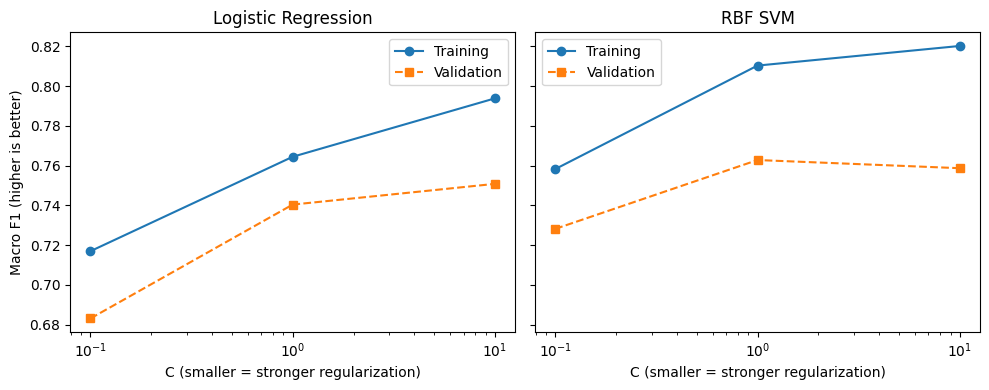

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, algorithm in zip(axes, ['Logistic Regression', 'RBF SVM']):
    rows = comparison[comparison['algorithm'] == algorithm]
    ax.plot(rows['C'], rows['train_macro_f1'], 'o-', label='Training')
    ax.plot(rows['C'], rows['validation_macro_f1'], 's--', label='Validation')
    ax.set_xscale('log')
    ax.set_xlabel('C (smaller = stronger regularization)')
    ax.set_title(algorithm)
    ax.legend()
axes[0].set_ylabel('Macro F1 (higher is better)')
plt.tight_layout()
plt.show()


The solid line describes fit to training examples. The dashed line describes performance on validation examples. Read the actual values: stronger regularization may reduce overfitting, but it can also underfit. We do not assume the smallest C must win.

### C. Freeze the validation choice, then compare test performance
Choose each algorithm’s C using validation only. Refit its selected pipeline on training + validation. Evaluate the two fixed choices on the same historical test. The overall learning model is selected by validation macro F1, never by the test table.

In [9]:
# Freeze choices before reading test scores.
family_winners = []
for algorithm in ['Logistic Regression', 'RBF SVM']:
    options = [row for row in candidates if row['algorithm'] == algorithm]
    best = options[0]
    for row in options[1:]:
        if row['validation_macro_f1'] > best['validation_macro_f1']:
            best = row
    family_winners.append(best)
best = family_winners[0]
for row in family_winners[1:]:
    if row['validation_macro_f1'] > best['validation_macro_f1']:
        best = row
selected_algorithm, selected_C = best['algorithm'], best['C']
print('Frozen choice:', selected_algorithm, 'C =', selected_C)

test_rows = []
for row in family_winners:
    fitted = clone(row['pipeline']).fit(X_development, y_development)
    predicted = fitted.predict(X_test)
    test_rows.append({'algorithm':row['algorithm'], 'selected_C':row['C'],
        'test_accuracy':accuracy_score(y_test, predicted),
        'test_macro_f1':f1_score(y_test, predicted, average='macro', zero_division=0),
        'test_weighted_f1':f1_score(y_test, predicted, average='weighted', zero_division=0)})
    if row['algorithm'] == selected_algorithm:
        model = fitted
predictions = model.predict(X_test)
display(pd.DataFrame(test_rows))
print(classification_report(y_test, predictions, zero_division=0))
print('Selected test accuracy:', accuracy_score(y_test, predictions))


Frozen choice: RBF SVM C = 1


/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/abhinavsharma/Documents/ChatGPT/AgriOptima-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = gra

,algorithm,selected_C,test_accuracy,test_macro_f1,test_weighted_f1
0,Logistic Regression,10,0.761981,0.729553,0.755492
1,RBF SVM,1,0.798722,0.756520,0.786602


              precision    recall  f1-score   support

   Soyabeans       0.57      1.00      0.72        26
       apple       1.00      1.00      1.00        27
      banana       1.00      1.00      1.00        29
       beans       0.40      0.40      0.40        20
   blackgram       1.00      1.00      1.00        20
    chickpea       0.00      0.00      0.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        29
      cotton       1.00      1.00      1.00        26
     cowpeas       0.40      0.50      0.44        20
      grapes       1.00      1.00      1.00        25
  groundnuts       0.26      0.25      0.26        20
        jute       0.87      1.00      0.93        20
 kidneybeans       0.36      0.40      0.38        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        30
       mango       1.00      1.00      1.00        26
   mothbeans       0.29    

Explain which algorithm has higher validation macro F1 and why it was selected. Then discuss the test results and weak classes. A test score can be lower than a validation score; this does not justify changing C after seeing the test.

In [10]:
# 6. Predict one example. The answer is a dataset class, not guaranteed farm advice.
example = X_test.iloc[[0]]
print("Example crop:", model.predict(example)[0])

Example crop: peas


## 4. Figures and interpretation
These figures use held-out predictions when labels exist. For soil, they describe the held-out groups or scores.

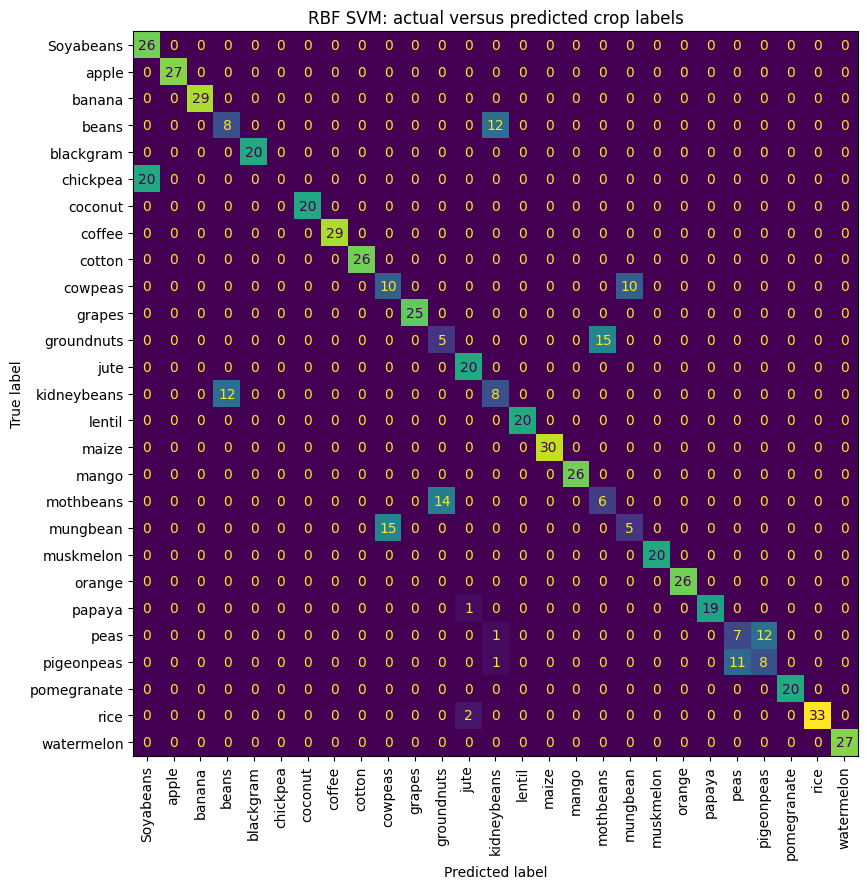

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, ax=ax, xticks_rotation=90, colorbar=False)
plt.title(f'{selected_algorithm}: actual versus predicted crop labels')
plt.tight_layout()
plt.show()

Diagonal cells are correct classifications. Off-diagonal cells show which crop labels are confused. The matrix is a test of label prediction, not a field trial.

## 5. Save this learning model separately
The working application models remain unchanged. The saved bundle includes the features and preprocessing needed for later use. This is the holdout experiment model, not an all-data production refit.

In [12]:
import joblib
output = ROOT / 'saved_models'
output.mkdir(exist_ok=True)
bundle = {'model': model, 'features': features}
joblib.dump(bundle, output / '01_crop_suitability.joblib')
print('Learning artifact saved separately.')

Learning artifact saved separately.


## 6. Viva summary and limitations
Seven measurements predict one crop label. Logistic Regression and SVM are compared below. Classification accuracy means agreement with dataset labels, not proof of the best profitable crop. Some classes, including chickpea, have weak recall.

Explain: source and target, cleaning choices, split, preprocessing, algorithm, metric, baseline (if applicable), and one limitation. Fitted preprocessing must also be used for new requests. No custom Python functions or classes are defined in this notebook.

### Course checklist for this notebook
EDA: class counts and data-quality checks. Features: seven measured inputs with units and scaling. Classification: Logistic Regression and SVM. Regularization: compare C with training/validation curves. Tuning: choose C using validation macro F1. Performance: compare accuracy, macro/weighted F1 and confusion matrix. Ensemble learning is demonstrated in the crop-yield notebook. These learning artifacts do not replace the website’s saved SVM automatically.

### Read this run’s results
Validation selected the RBF SVM with C=1. Its reused historical test accuracy is approximately 79.87% and macro F1 is 0.757, compared with Logistic Regression accuracy 76.20% and macro F1 0.730. The SVM performs better in this comparison, but the per-class report still matters: a single average does not establish reliable performance for every crop or a new farm.